# 27 — Basis strata: stratifying the ring base by birth commit

Validates [`docs/EWM_BASIS_STRATA.md`](../docs/EWM_BASIS_STRATA.md) numerically
on real HLLSets (the bit-exact Python mirror of the soldered morphism used by
notebooks 22–26), over a synthetic 10-scene clip with a simulated linear
`t:<sha1>` commit chain.

| § | claim | check |
| - | - | - |
| 2 | the birth residuals `R_i` form a basis adapted to the flag `0 ⊂ span_1 ⊂ … ⊂ span_t` | distinct pivots, `R_i ∈ span_i \ span_{i-1}`, unit-vector coordinates, `cover(R) = U` |
| 2 | the current RREF slots rotate; the birth residuals are the stable identities | slot `i ≠ R_i` after later births; replay determinism |
| 3 | host LLM context: strata as the context unit | `recent / skeleton+recent / budget / delta_since` policies; coverage vs the originals window |
| 4 | trajectory ambiguity: membership, signature, cross-world test, time travel | spanning-prefix localization, generation signatures differ under reordering, foreign state rejected, spill collapses at the explaining commit |

Honest scope: the commit chain is *simulated* (one `t:` per frame, like
`ewm-app`'s `ids=` messages), the clip is synthetic, and CIDs are 12-char
truncations. The algebra is the real one — the same GF(2)/lattice operations
the Rust ring uses.


## §0 — Environment and the soldered morphism

Pinned exactly as in notebooks 22–26: `reg = hash & 1023`,
`tz = trailing_zeros(hash >> 10)`, `bit = reg*32 + tz`, MurmurHash3 x64-128
lower 64 bits; the `tid0` test vector pins the hash.


In [1]:
import hashlib
import pathlib
import random

import mmh3
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt


def find_root(start):
    for anc in [start, *list(start.parents)[:4]]:
        for cand in [anc, *[p for p in anc.iterdir() if p.is_dir()]]:
            if (cand / "crates" / "ewm-boolring").exists():
                return cand
    return None


ROOT = find_root(pathlib.Path.cwd())
assert ROOT is not None, "run this notebook from the repo or its notebooks/ directory"

P, M, BITS_PER_REG = 10, 1024, 32
TOTAL_BITS = M * BITS_PER_REG
PLANE_BYTES = TOTAL_BITS // 8
assert mmh3.hash64(b"tid0", seed=0, signed=False)[0] == 2_892_634_914_804_110_692

CHECKS = []


def law(name, ok):
    ok = bool(ok)
    CHECKS.append((name, ok))
    print("  %-62s %s" % (name, "ok" if ok else "FAIL"))
    return ok


def site(tok):
    h = mmh3.hash64(tok.encode(), seed=0, signed=False)[0]
    reg = h & (M - 1)
    rem = h >> P
    tz = 31 if rem == 0 else min((rem & -rem).bit_length() - 1, 31)
    return reg * BITS_PER_REG + tz


def hllset(tokens):
    m = 0
    for t in tokens:
        m |= 1 << site(t)
    return m


popcount = int.bit_count
union = lambda a, b: a | b
intersection = lambda a, b: a & b
difference = lambda a, b: a & ~b
symmetric_difference = lambda a, b: a ^ b


def hcid(x):
    """h:<sha1> content key of a set (12-char, the notebook convention)."""
    return "h:" + hashlib.sha1(x.to_bytes(PLANE_BYTES, "big")).hexdigest()[:12]


def tcid(i):
    """A simulated commit t:<sha1> for frame i (0-based) — the ewm-app ids= message."""
    return "t:" + hashlib.sha1(f"ids={i+1}".encode()).hexdigest()[:12]


def lowest_bit(x):
    return (x & -x).bit_length() - 1


def has_bit(x, p):
    return (x >> p) & 1 == 1


print("repo  :", ROOT)
print("plane : %d bits | mmh3 pinned OK" % TOTAL_BITS)


repo  : /home/alexmy/SGS/SGS_lib/fractal_manifold_gen2/ewm-state-machine
plane : 32768 bits | mmh3 pinned OK


## §1 — A synthetic trajectory with one commit per frame

Same clip shape as notebook 22: 10 scenes × 10 frames, a 200-token scene
base plus 56 drift tokens per frame. Every frame brings drift bits, so every
frame is a *materialized* commit; the basis-change events (the future
`BirthTable` rows) are a subset of the commit chain. Commit CIDs are the
`t:<sha1>` of the same `ids=` message `ewm-app` writes.


In [2]:
SCENES, FRAMES_PER_SCENE = 10, 10
BASE_TOKENS, DRIFT_TOKENS = 200, 56
TRUE_CUTS = [1 + s * FRAMES_PER_SCENE for s in range(1, SCENES)]  # 1-based ids

clip_tokens, clip_sets = [], []
for s in range(SCENES):
    base = [f"s{s}_w{j}" for j in range(BASE_TOKENS)]
    for f in range(FRAMES_PER_SCENE):
        t = s * FRAMES_PER_SCENE + f
        toks = base + [f"d{t}_{j}" for j in range(DRIFT_TOKENS)]
        clip_tokens.append(toks)
        clip_sets.append(hllset(toks))

commits = [tcid(i) for i in range(len(clip_sets))]
originals = [hcid(x) for x in clip_sets]
lattice_top = 0
for x in clip_sets:
    lattice_top |= x

print("clip: %d frames (%d scenes x %d), %d tokens/frame"
      % (len(clip_sets), SCENES, FRAMES_PER_SCENE, len(clip_tokens[0])))
print("commit chain: %s ... %s" % (commits[0], commits[-1]))
print("lattice top |U| = %d bits" % popcount(lattice_top))
law("every frame is a materialized commit (drift tokens bring new bits)",
    len(commits) == len(clip_sets))
law("the commit chain is content-addressed and duplicate-free",
    len(set(commits)) == len(commits))


clip: 100 frames (10 scenes x 10), 256 tokens/frame
commit chain: t:c8880abafefc ... t:b5f9e4554cbe
lattice top |U| = 3294 bits
  every frame is a materialized commit (drift tokens bring new bits) ok
  the commit chain is content-addressed and duplicate-free       ok


True

## §2 — BirthTable: recording the flag basis

Line-for-line mirror of `BoolBasis` (notebook 22), plus the one new piece:
`record_trajectory` keeps the `Added { residual, pivot, rotation_count }` of
every basis-change event. That is the **BirthTable** — one row per stratum,
linked to the commit that caused it. The residuals `R_i` are the flag basis;
the RREF `basis.basis` slots are the working coordinates and rotate.

The flag laws checked here are the exact claims of
`docs/EWM_BASIS_STRATA.md` §1–2.


In [3]:
class BoolBasis:
    """Row-echelon GF(2) basis over HLLSets (Rust `BoolBasis`)."""

    def __init__(self):
        self.basis = []    # HLLSets as int bitmasks
        self.pivots = []   # leading (lowest) bit of each basis element

    def dimension(self):
        return len(self.basis)

    def reduce(self, x):
        used = []
        while x:
            p = lowest_bit(x)
            if p in self.pivots:
                j = self.pivots.index(p)
                x ^= self.basis[j]
                used.append(j)
            else:
                return x, used
        return 0, used

    def residual(self, x):
        return self.reduce(x)[0]

    def coordinates(self, x):
        res, used = self.reduce(x)
        if res:
            return None
        coords = [False] * len(self.basis)
        for j in used:
            coords[j] = not coords[j]
        return coords

    def insert(self, x):
        res, used = self.reduce(x)
        if not res:
            return {"added": False, "coords": used}
        p = lowest_bit(res)
        rotation_count = 0
        for j, b in enumerate(self.basis):
            if has_bit(b, p):
                self.basis[j] = b ^ res
                rotation_count += 1
        self.pivots.append(p)
        self.basis.append(res)
        return {"added": True, "residual": res, "pivot": p,
                "rotation_count": rotation_count}

    def cover(self):
        c = 0
        for b in self.basis:
            c |= b
        return c

    def clone(self):
        b = BoolBasis()
        b.basis = list(self.basis)
        b.pivots = list(self.pivots)
        return b


class BirthRecord:
    """One stratum: the birth residual R_g and the commit that caused it."""

    __slots__ = ("generation", "commit", "original", "residual", "pivot",
                 "rotation_count", "push_index")

    def __init__(self, generation, commit, original, residual, pivot,
                 rotation_count, push_index):
        self.generation = generation
        self.commit = commit
        self.original = original
        self.residual = residual
        self.pivot = pivot
        self.rotation_count = rotation_count
        self.push_index = push_index


def record_trajectory(sets, commits, originals):
    """Push every original; record a BirthRecord on each Added event."""
    basis = BoolBasis()
    records = []
    for i, x in enumerate(sets):
        res = basis.insert(x)
        if res["added"]:
            records.append(BirthRecord(
                generation=len(records),
                commit=commits[i],
                original=originals[i],
                residual=res["residual"],
                pivot=res["pivot"],
                rotation_count=res["rotation_count"],
                push_index=i,
            ))
    return basis, records


def flag_reduce(rs, pivots, x, k=None):
    """Reduce x against the flag prefix R_0..R_{k-1} (k=None: all)."""
    if k is None:
        k = len(rs)
    used = []
    while x:
        p = lowest_bit(x)
        j = None
        for jj in range(k):
            if pivots[jj] == p:
                j = jj
                break
        if j is None:
            return x, used
        x ^= rs[j]
        used.append(j)
    return 0, used


def flag_coords(rs, pivots, x):
    res, used = flag_reduce(rs, pivots, x)
    if res:
        return None
    coords = [False] * len(rs)
    for j in used:
        coords[j] = not coords[j]
    return coords


def births_up_to(records, i):
    return sum(1 for b in records if b.push_index <= i)


basis, births = record_trajectory(clip_sets, commits, originals)
t = len(births)
flag_rs = [b.residual for b in births]
flag_pivots = [b.pivot for b in births]

print("basis dimension:", basis.dimension(), "| birth strata:", t)
print("structural commits: %d of %d" % (t, len(clip_sets)))
print("total rotations (slots re-pivoted):", sum(b.rotation_count for b in births))

law("flag pivots are distinct in birth order", len(set(flag_pivots)) == t)
law("each birth residual is a unit vector in the flag basis (R_i -> e_i)",
    all(flag_reduce(flag_rs, flag_pivots, flag_rs[i])[1] == [i] for i in range(t)))
law("each birth residual lies outside the earlier span (R_i notin span_{i-1})",
    all(flag_reduce(flag_rs, flag_pivots, flag_rs[i], i)[0] != 0 for i in range(t)))
law("span chain: each original is spanned by the strata born up to its push",
    all(flag_reduce(flag_rs, flag_pivots, clip_sets[i],
                    births_up_to(births, i))[0] == 0
        for i in range(len(clip_sets))))
law("rotations happened: some RREF slot differs from its birth residual",
    any(basis.basis[i] != flag_rs[i] for i in range(t)))

basis2, births2 = record_trajectory(clip_sets, commits, originals)
law("determinism: replay gives the same pivots and residuals",
    [b.pivot for b in births2] == flag_pivots
    and [b.residual for b in births2] == flag_rs)

flag_cover = 0
for r in flag_rs:
    flag_cover |= r
law("cover(R) = union(originals) = lattice top", flag_cover == lattice_top)


basis dimension: 100 | birth strata: 100
structural commits: 100 of 100
total rotations (slots re-pivoted): 534
  flag pivots are distinct in birth order                        ok
  each birth residual is a unit vector in the flag basis (R_i -> e_i) ok
  each birth residual lies outside the earlier span (R_i notin span_{i-1}) ok
  span chain: each original is spanned by the strata born up to its push ok
  rotations happened: some RREF slot differs from its birth residual ok
  determinism: replay gives the same pivots and residuals        ok
  cover(R) = union(originals) = lattice top                      ok


True

## §3 — Host LLM context: strata as the context unit

The ring's visibility window feeds the host the last `K` *originals*; the
birth table feeds it the last `K` *strata* instead — one object per new
degree of freedom, each with a birth commit. Four policies from the design
note, plus the coverage each context gives over the lattice top `U`.


In [4]:
def policy_recent(births, K):
    return births[-K:]


def policy_skeleton_recent(births, s, K):
    return births[:s] + births[-K:]


def policy_budget(births, B):
    """Newest strata first, then the largest; greedy until the bit budget."""
    sel, total = [], 0
    for b in sorted(births, key=lambda b: (-b.generation, -popcount(b.residual))):
        if total + popcount(b.residual) <= B:
            sel.append(b)
            total += popcount(b.residual)
    return sel, total


def policy_delta_since(births, commit_index):
    return [b for b in births if b.push_index > commit_index]


K = 10
rec = policy_recent(births, K)
law("recent(K): exactly the last K strata",
    [b.generation for b in rec] == list(range(t - K, t)))

skel = policy_skeleton_recent(births, 5, 8)
gens = {b.generation for b in skel}
law("skeleton+recent: keeps the oldest s and the newest K",
    set(range(5)).issubset(gens) and set(range(t - 8, t)).issubset(gens))

sel, total = policy_budget(births, 4000)
law("budget(B): the selected strata fit the bit budget", total <= 4000)
law("budget(B): every selected stratum is a real stratum",
    all(0 <= b.generation < t for b in sel))

delta = policy_delta_since(births, 89)
law("delta_since(c): only strata born after commit c",
    len(delta) > 0 and all(b.push_index > 89 for b in delta))

cov_all = 0
for b in births:
    cov_all |= b.residual
law("all strata together cover the lattice top exactly",
    popcount(lattice_top & cov_all) == popcount(lattice_top))
law("strata are no more numerous than originals (t <= n)", t <= len(clip_sets))

print("\nstratum digest (last 5 strata) — the context the host sees:")
print("  g   commit      |R|  pivot  rot")
for b in births[-5:]:
    print("  %-3d %s  %4d  %5d  %3d"
          % (b.generation, b.commit, popcount(b.residual), b.pivot,
             b.rotation_count))


  recent(K): exactly the last K strata                           ok
  skeleton+recent: keeps the oldest s and the newest K           ok
  budget(B): the selected strata fit the bit budget              ok
  budget(B): every selected stratum is a real stratum            ok
  delta_since(c): only strata born after commit c                ok
  all strata together cover the lattice top exactly              ok
  strata are no more numerous than originals (t <= n)            ok

stratum digest (last 5 strata) — the context the host sees:
  g   commit      |R|  pivot  rot
  95  t:807a087d147f  1200    289    1
  96  t:f64b54f27cc0   581   1024   25
  97  t:36d95123b653   246     37    0
  98  t:eaeb36541ef8   282   1216   30
  99  t:b5f9e4554cbe   352   1152   35


## §4 — Trajectory ambiguity: membership, signature, cross-world, time travel

Take a state `X` (the scene-2 cut frame). The flag answers, without any
model: *is `X` consistent with this lineage up to commit `k`?* (membership),
*which strata are needed to rebuild it?* (hard signature), *which lineage
does a foreign state belong to?* (cross-world residual), and *at which
commit does the past first explain it?* (spill collapse / time travel).


In [5]:
m = TRUE_CUTS[1] - 1          # 0-based index of the scene-2 cut frame
X = clip_sets[m]

# ── membership: the first flag-prefix length that spans X ───────────────────
first_zero = None
for k in range(t + 1):
    if flag_reduce(flag_rs, flag_pivots, X, k)[0] == 0:
        first_zero = k
        break
bup = births_up_to(births, m)
print("X = frame %d (scene-2 cut) | first spanning prefix k*=%d | strata born "
      "up to X's commit=%d" % (m + 1, first_zero, bup))
law("membership: X is explained by the strata born at or before its commit",
    first_zero <= bup)

# ── hard signature in lineage A ─────────────────────────────────────────────
coords_A = flag_coords(flag_rs, flag_pivots, X)
sig_A = {j for j, c in enumerate(coords_A) if c}
law("hard signature: only strata born <= X's commit are used",
    all(births[j].push_index <= m for j in sig_A))
recon = 0
for j in sig_A:
    recon ^= flag_rs[j]
law("hard signature reconstructs X exactly", recon == X)

# ── same content, different history: reordered lineage B ────────────────────
order_B = list(range(len(clip_sets)))
random.Random(7).shuffle(order_B)
sets_B = [clip_sets[i] for i in order_B]
commits_B = [commits[i] for i in order_B]
originals_B = [originals[i] for i in order_B]
basis_B, births_B = record_trajectory(sets_B, commits_B, originals_B)
flag_rs_B = [b.residual for b in births_B]
flag_pivots_B = [b.pivot for b in births_B]
law("same originals, different order -> same final span (same dimension)",
    basis_B.dimension() == basis.dimension())

diff_frames = []
for mm in [TRUE_CUTS[0] - 1, m, TRUE_CUTS[2] - 1]:
    XX = clip_sets[mm]
    sA = {j for j, c in enumerate(flag_coords(flag_rs, flag_pivots, XX)) if c}
    sB = {j for j, c in enumerate(flag_coords(flag_rs_B, flag_pivots_B, XX)) if c}
    if sA != sB:
        diff_frames.append(mm)
law("same content, different history -> different generation signature",
    len(diff_frames) > 0)
coords_B = flag_coords(flag_rs_B, flag_pivots_B, X)
sig_B = {j for j, c in enumerate(coords_B) if c}
print("  sig_A =", sorted(sig_A)[:10], "...  (lineage A)")
print("  sig_B =", sorted(sig_B)[:10], "...  (lineage B, shuffled order)")

# ── cross-world: a foreign token lineage A has never seen ───────────────────
probe = None
for j in range(1_000_000):
    cand = f"z{j}"
    if not has_bit(lattice_top, site(cand)):
        probe = cand
        break
assert probe is not None, "the plane has room for a foreign site"
X_C = hllset([probe])
basis_C, births_C = record_trajectory([X_C], ["t:" + "c" * 12], [hcid(X_C)])
flag_rs_C = [b.residual for b in births_C]
flag_pivots_C = [b.pivot for b in births_C]
res_A = flag_reduce(flag_rs, flag_pivots, X_C)[0]
res_C = flag_reduce(flag_rs_C, flag_pivots_C, X_C)[0]
law("cross-world: a foreign state is outside lineage A's span", res_A != 0)
law("cross-world: the same state is inside its own lineage's span", res_C == 0)
soft_C = [popcount(X_C & r) / popcount(r) for r in flag_rs]
law("soft signature: the foreign state has an all-zero profile in A",
    all(w == 0.0 for w in soft_C))

# ── soft signature of X (always defined) ────────────────────────────────────
soft_X = [popcount(X & r) / popcount(r) for r in flag_rs]
top = sorted(range(len(soft_X)), key=lambda j: -soft_X[j])[:3]
law("soft signature of X is a valid profile in [0,1]",
    all(0.0 <= w <= 1.0 for w in soft_X))
law("soft signature of X has positive support", any(w > 0 for w in soft_X))
print("  top soft strata of X:", [(j, round(soft_X[j], 2), births[j].commit)
                                 for j in top])

# ── time travel: spill collapse over the frame history ──────────────────────
class FrameSnapshot:
    def __init__(self, basis, cover):
        self.basis = basis
        self.cover = cover


snapshots = []
bb = BoolBasis()
for i, x in enumerate(clip_sets):
    bb.insert(x)
    snapshots.append(FrameSnapshot(bb.clone(), bb.cover()))

spills = []
for k in range(len(clip_sets)):
    snap = snapshots[k]
    spill = popcount(X & ~snap.cover)
    spills.append(spill)

first_collapse = next(
    k for k, s in enumerate(spills)
    if s == 0 and snapshots[k].basis.coordinates(X) is not None)
law("time travel: at X's own commit the spill is 0 and the hard key exists",
    spills[m] == 0 and snapshots[m].basis.coordinates(X) is not None)
law("time travel: the spill collapses at or before X's commit",
    first_collapse <= m)
print("  spill first collapses at frame k=%d (X is frame %d)"
      % (first_collapse + 1, m + 1))


X = frame 21 (scene-2 cut) | first spanning prefix k*=21 | strata born up to X's commit=21
  membership: X is explained by the strata born at or before its commit ok
  hard signature: only strata born <= X's commit are used        ok
  hard signature reconstructs X exactly                          ok
  same originals, different order -> same final span (same dimension) ok
  same content, different history -> different generation signature ok
  sig_A = [20] ...  (lineage A)
  sig_B = [40] ...  (lineage B, shuffled order)
  cross-world: a foreign state is outside lineage A's span       ok
  cross-world: the same state is inside its own lineage's span   ok
  soft signature: the foreign state has an all-zero profile in A ok
  soft signature of X is a valid profile in [0,1]                ok
  soft signature of X has positive support                       ok
  top soft strata of X: [(20, 1.0, 't:d6e918bf9881'), (21, 0.79, 't:2f55a2a3a937'), (24, 0.79, 't:d419f23d9652')]
  time travel: at X'

  coverage curves are monotone in K                              ok


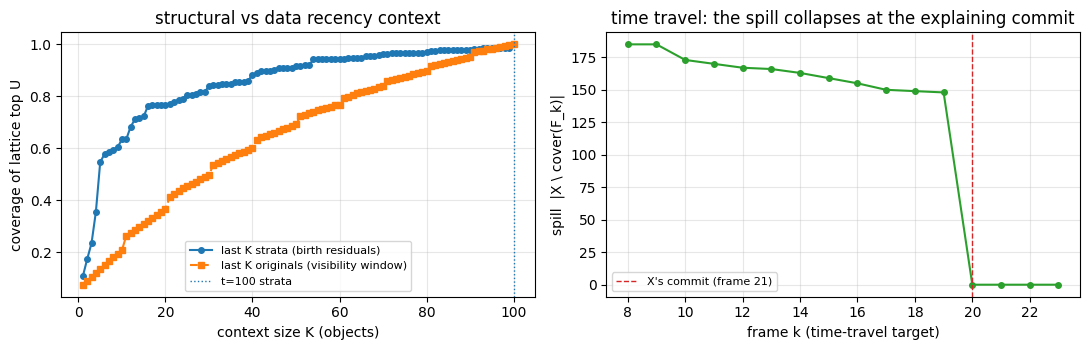

In [6]:
Ks = list(range(1, len(clip_sets) + 1))
cov_strata, cov_orig = [], []
U = lattice_top
for K in Ks:
    c_s = 0
    for b in births[-K:]:
        c_s |= b.residual
    cov_strata.append(popcount(U & c_s) / popcount(U))
    c_o = 0
    for x in clip_sets[-K:]:
        c_o |= x
    cov_orig.append(popcount(U & c_o) / popcount(U))

law("coverage curves are monotone in K",
    all(cov_strata[i] <= cov_strata[i + 1] for i in range(len(Ks) - 1))
    and all(cov_orig[i] <= cov_orig[i + 1] for i in range(len(Ks) - 1)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.plot(Ks, cov_strata, "o-", ms=4, label="last K strata (birth residuals)")
ax1.plot(Ks, cov_orig, "s--", ms=4, label="last K originals (visibility window)")
ax1.axvline(t, color="tab:blue", ls=":", lw=1, label=f"t={t} strata")
ax1.set_xlabel("context size K (objects)")
ax1.set_ylabel("coverage of lattice top U")
ax1.set_title("structural vs data recency context")
ax1.legend(fontsize=8)
ax1.grid(alpha=0.3)

win = range(max(0, m - 12), min(len(spills), m + 4))
ax2.plot(list(win), [spills[k] for k in win], "o-", ms=4, color="tab:green")
ax2.axvline(m, color="tab:red", ls="--", lw=1,
            label=f"X's commit (frame {m + 1})")
ax2.set_xlabel("frame k (time-travel target)")
ax2.set_ylabel(r"spill  |X \ cover(F_k)|")
ax2.set_title("time travel: the spill collapses at the explaining commit")
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Summary

The prototype supports `docs/EWM_BASIS_STRATA.md`:

- **§2** the birth residuals form the flag basis: distinct pivots, unit-vector
  coordinates, strict growth `R_i ∈ span_i \ span_{i-1}`, `cover(R) = U`, and
  they are stable while the RREF slots rotate; replay is deterministic.
- **§3** strata are the structural context unit: the four policies work, all
  strata cover `U` exactly, and the strata curve reaches full coverage in
  `t ≤ n` objects — the compressed, provenance-bearing form of the
  originals window.
- **§4** a state is localized to the commit that first explains it; the hard
  signature distinguishes the same content under different histories; the
  cross-world residual rejects a foreign lineage; the soft signature is a
  valid, always-defined profile; and time travel's spill collapses exactly at
  the explaining commit.

The Rust next step is unchanged: `ewm-boolring::BirthTable` as a recording
wrapper around `BoolWindow::push`, wired through `StateCache::restore`'s
existing replay.


In [7]:
passed = sum(1 for _, ok in CHECKS if ok)
print("checks: %d/%d passed" % (passed, len(CHECKS)))
assert all(ok for _, ok in CHECKS), "a law failed"
print("strata=%d  originals=%d  dimension=%d  rotations=%d"
      % (t, len(clip_sets), basis.dimension(),
         sum(b.rotation_count for b in births)))
print("docs: EWM_BASIS_STRATA.md — prototype confirms the design; "
      "BirthTable is the next Rust step")


checks: 29/29 passed
strata=100  originals=100  dimension=100  rotations=534
docs: EWM_BASIS_STRATA.md — prototype confirms the design; BirthTable is the next Rust step
